In [8]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from utils.libanaly import Plot_Background,plot_quivers,CircleCalc
from scipy.optimize import curve_fit

In [25]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy.interpolate
import scipy.integrate
from scipy.ndimage import gaussian_filter
from copy import deepcopy

class ImageS:

    Intensity_max = 0.00175

    def __init__(self, data, blur=True):
        # self.data = np.flip(data.swapaxes(0,1),axis=1)
        # self.data = data.swapaxes(0,1)
        self.data = data
        self.shape = data[:, :, 0].shape[0]
        # self.res = round(self.shape*2/80.)
        self.res = (self.shape - 1) / 46.2262
        self.Get_Grid()
        self.Filter(blur=blur)
        self.max_LP = np.max(self.amp)

    def Get_Grid(self):
        xgrid = np.linspace(-23.1131, 23.1131, self.shape, endpoint=False)
        ygrid = np.linspace(-23.1131, 23.1131, self.shape, endpoint=False)
        diff = np.diff(xgrid)[0] / 2.0
        xgrid += diff
        ygrid += diff
        self.xmesh, self.ymesh = np.meshgrid(xgrid, ygrid, indexing="ij")

    def Filter(self, blur=True):
        I0, Q0, U0, V0 = (
            self.data[:, :, 0],
            self.data[:, :, 1],
            self.data[:, :, 2],
            self.data[:, :, 3],
        )
        if blur == True:
            gausian_kernal = 2.16871  # * 1.558722, 20uas = 2.16871
            # gausian_kernal=0 # kernel?
            self.I = gaussian_filter(I0, gausian_kernal * self.res)
            self.Q = gaussian_filter(Q0, gausian_kernal * self.res)
            self.U = gaussian_filter(U0, gausian_kernal * self.res)
            self.V = gaussian_filter(V0, gausian_kernal * self.res)
            self.I0 = I0
            iQ = scipy.interpolate.RectBivariateSpline(
                self.xmesh[:, 0], self.ymesh[0, :], self.Q
            )
            iU = scipy.interpolate.RectBivariateSpline(
                self.xmesh[:, 0], self.ymesh[0, :], self.U
            )
            iI = scipy.interpolate.RectBivariateSpline(
                self.xmesh[:, 0], self.ymesh[0, :], self.I
            )
            iV = scipy.interpolate.RectBivariateSpline(
                self.xmesh[:, 0], self.ymesh[0, :], self.V
            )
            iI0 = scipy.interpolate.RectBivariateSpline(
                self.xmesh[:, 0], self.ymesh[0, :], self.I0
            )
            rotation_angle = 0.6 * np.pi
            # rotation_angle = 0
            x, y = np.meshgrid(np.arange(64), np.arange(64), indexing="ij")
            xv = (x - 63 / 2.0) * 0.518838 * np.cos(rotation_angle) + (
                y - 63 / 2.0
            ) * 0.518838 * np.sin(rotation_angle)
            yv = -(x - 63 / 2.0) * 0.518838 * np.sin(rotation_angle) + (
                y - 63 / 2.0
            ) * 0.518838 * np.cos(rotation_angle)
            self.I = iI.ev(xv, yv)
            self.Q = iQ.ev(xv, yv) * np.cos(2 * rotation_angle) - iU.ev(
                xv, yv
            ) * np.sin(2 * rotation_angle)
            self.U = iQ.ev(xv, yv) * np.sin(2 * rotation_angle) + iU.ev(
                xv, yv
            ) * np.cos(2 * rotation_angle)
            self.V = iV.ev(xv, yv)
            self.I0 = iI0.ev(xv, yv)
            self.shape = 64
            self.data = [idata[18:81, 18:81] for idata in self.data]
            xgrid = np.linspace(-16.3434, 16.3434, self.shape, endpoint=False)
            ygrid = np.linspace(-16.3434, 16.3434, self.shape, endpoint=False)
            diff = np.diff(xgrid)[0] / 2.0
            xgrid += diff
            ygrid += diff
            self.xmesh, self.ymesh = np.meshgrid(xgrid, ygrid, indexing="ij")
            self.evpa = (180.0 / np.pi) * 0.5 * np.arctan2(self.U, self.Q)
            self.amp = np.sqrt(self.Q**2 + self.U**2)
            self.Create_EVPA_Dataset()
        else:
            gausian_kernal = 0  # * 1.558722, 20uas = 2.16871
            # gausian_kernal=0 # kernel?
            self.I = gaussian_filter(I0, gausian_kernal * self.res)
            self.Q = gaussian_filter(Q0, gausian_kernal * self.res)
            self.U = gaussian_filter(U0, gausian_kernal * self.res)
            self.V = gaussian_filter(V0, gausian_kernal * self.res)
            self.I0 = I0
            iQ = scipy.interpolate.RectBivariateSpline(
                self.xmesh[:, 0], self.ymesh[0, :], self.Q
            )
            iU = scipy.interpolate.RectBivariateSpline(
                self.xmesh[:, 0], self.ymesh[0, :], self.U
            )
            iI = scipy.interpolate.RectBivariateSpline(
                self.xmesh[:, 0], self.ymesh[0, :], self.I
            )
            iV = scipy.interpolate.RectBivariateSpline(
                self.xmesh[:, 0], self.ymesh[0, :], self.V
            )
            iI0 = scipy.interpolate.RectBivariateSpline(
                self.xmesh[:, 0], self.ymesh[0, :], self.I0
            )
            rotation_angle = 0.6 * np.pi
            # rotation_angle = 0
            x, y = np.meshgrid(
                np.arange(self.shape), np.arange(self.shape), indexing="ij"
            )
            xv = (x - (self.shape - 1.0) / 2.0) * 63 / (
                self.shape - 1
            ) * 0.518838 * np.cos(rotation_angle) + (
                y - (self.shape - 1.0) / 2.0
            ) * 63 / (
                self.shape - 1
            ) * 0.518838 * np.sin(
                rotation_angle
            )
            yv = -(x - (self.shape - 1.0) / 2.0) * 63 / (
                self.shape - 1
            ) * 0.518838 * np.sin(rotation_angle) + (
                y - (self.shape - 1.0) / 2.0
            ) * 63 / (
                self.shape - 1
            ) * 0.518838 * np.cos(
                rotation_angle
            )
            # xv = np.array([[(x-(self.shape-1.)/2.0)*63/(self.shape-1)*0.518838*np.cos(rotation_angle)+(y-(self.shape-1.)/2.0)*63/(self.shape-1)*0.518838*np.sin(rotation_angle) for y in range(self.shape)] for x in range(self.shape)])
            # yv = np.array([[-(x-(self.shape-1.)/2.0)*63/(self.shape-1)*0.518838*np.sin(rotation_angle)+(y-(self.shape-1.)/2.0)*63/(self.shape-1)*0.518838*np.cos(rotation_angle) for y in range(self.shape)] for x in range(self.shape)])
            # yv = np.array([[(x-31.5)*0.518838*np.cos(-0.*np.pi)-(y-31.5)*0.518838*np.sin(-0.*np.pi) for x in range(64)] for y in range(64)])
            # xv = np.array([[(x-31.5)*0.518838*np.sin(-0.*np.pi)+(y-31.5)*0.518838*np.cos(-0.*np.pi) for x in range(64)] for y in range(64)])
            # print(f'x_gap:{np.max(xv)-np.min(xv)}')
            # print(f'y_gap:{np.max(yv)-np.min(yv)}')
            self.I = iI.ev(xv, yv)
            self.Q = iQ.ev(xv, yv) * np.cos(2 * rotation_angle) - iU.ev(
                xv, yv
            ) * np.sin(2 * rotation_angle)
            self.U = iQ.ev(xv, yv) * np.sin(2 * rotation_angle) + iU.ev(
                xv, yv
            ) * np.cos(2 * rotation_angle)
            self.V = iV.ev(xv, yv)
            self.I0 = iI0.ev(xv, yv)
            # self.shape = 64
            # self.data = [idata[18:81,18:81] for idata in self.data]
            xgrid = np.linspace(-16.3434, 16.3434, self.shape, endpoint=False)
            ygrid = np.linspace(-16.3434, 16.3434, self.shape, endpoint=False)
            diff = np.diff(xgrid)[0] / 2.0
            xgrid += diff
            ygrid += diff
            self.xmesh, self.ymesh = np.meshgrid(xgrid, ygrid, indexing="ij")
            self.evpa = (180.0 / np.pi) * 0.5 * np.arctan2(self.U, self.Q)
            self.amp = np.sqrt(self.Q**2 + self.U**2)
            # self.Create_EVPA_Dataset()

    def Plot_EVPA(self, ax, vmax=Intensity_max):

        scal = np.max(self.amp)
        vx = self.amp * np.cos(self.evpa * np.pi / 180.0) / scal
        vy = self.amp * np.sin(self.evpa * np.pi / 180.0) / scal

        skip = int(round(self.shape / 16))

        ax.axis("equal")
        ax.pcolormesh(
            self.xmesh,
            self.ymesh,
            self.I,
            cmap="afmhot",
            vmin=0,
            vmax=vmax,
            shading="auto",
        )
        ax.quiver(
            self.xmesh[::skip, ::skip],
            self.ymesh[::skip, ::skip],
            vx[::skip, ::skip],
            vy[::skip, ::skip],
            headwidth=1,
            headlength=1,
            width=0.005,
            color="green",
            units="width",
            scale=16,
        )

    def Plot_Quiver11(self, ax, color_in, max_LP, i, vmax=Intensity_max):
        mycmap = plt.get_cmap("gist_rainbow")
        colors = [mycmap(j) for j in np.linspace(0, 1, 17)]
        mynorm = matplotlib.colors.BoundaryNorm(
            range(0, 16, 1), ncolors=mycmap.N, clip=True
        )
        scal = np.max(self.amp)
        vx = self.amp * np.cos(self.evpa * np.pi / 180.0) / max_LP * 4
        vy = self.amp * np.sin(self.evpa * np.pi / 180.0) / max_LP * 4
        skip = int(round(self.shape / 8))
        c = i
        if i == 0:
            ax.quiver(
                self.xmesh[::skip, ::skip],
                self.ymesh[::skip, ::skip],
                vx[::skip, ::skip],
                vy[::skip, ::skip],
                color=color_in,
                headwidth=1,
                headlength=0.1,
                width=0.0015,
                units="width",
                scale=16,
            )
        else:
            ax.quiver(
                self.xmesh[::skip, ::skip],
                self.ymesh[::skip, ::skip],
                vx[::skip, ::skip],
                vy[::skip, ::skip],
                c,
                headwidth=1,
                headlength=0.1,
                width=0.0015,
                cmap=mycmap,
                norm=mynorm,
                units="width",
                scale=16,
            )

    def Plot_Quiver11_reverse(self, ax, color_in, max_LP, i, vmax=Intensity_max):
        mycmap = plt.get_cmap("gist_rainbow")
        colors = [mycmap(j) for j in np.linspace(0, 1, 17)]
        mynorm = matplotlib.colors.BoundaryNorm(
            range(0, 16, 1), ncolors=mycmap.N, clip=True
        )
        scal = np.max(self.amp)
        vx = -self.amp * np.cos(self.evpa * np.pi / 180.0) / max_LP * 4
        vy = -self.amp * np.sin(self.evpa * np.pi / 180.0) / max_LP * 4
        skip = int(round(self.shape / 8))
        c = i
        if i == 0:
            ax.quiver(
                self.xmesh[::skip, ::skip],
                self.ymesh[::skip, ::skip],
                vx[::skip, ::skip],
                vy[::skip, ::skip],
                color=color_in,
                headwidth=1,
                headlength=0.1,
                width=0.0015,
                units="width",
                scale=16,
            )
        else:
            ax.quiver(
                self.xmesh[::skip, ::skip],
                self.ymesh[::skip, ::skip],
                vx[::skip, ::skip],
                vy[::skip, ::skip],
                c,
                headwidth=1,
                headlength=0.1,
                width=0.0015,
                cmap=mycmap,
                norm=mynorm,
                units="width",
                scale=16,
            )

    def Plot_Quiver(self, ax, color_in, max_LP, i, vmax=Intensity_max):
        scal = np.max(self.amp)
        vx = self.amp * np.cos(self.evpa * np.pi / 180.0) / max_LP
        vy = self.amp * np.sin(self.evpa * np.pi / 180.0) / max_LP
        skip = int(round(self.shape / 16))
        c = i
        if i == 16:
            ax.quiver(
                self.xmesh[::skip, ::skip],
                self.ymesh[::skip, ::skip],
                vx[::skip, ::skip],
                vy[::skip, ::skip],
                color="green",
                headwidth=1,
                headlength=0.1,
                width=0.006,
                units="width",
                scale=16,
            )
        else:
            ax.quiver(
                self.xmesh[::skip, ::skip],
                self.ymesh[::skip, ::skip],
                vx[::skip, ::skip],
                vy[::skip, ::skip],
                color="green",
                headwidth=1,
                headlength=0.1,
                width=0.006,
                units="width",
                scale=16,
            )

    def Plot_Quiver_reverse(self, ax, color_in, max_LP, i, vmax=Intensity_max):
        mycmap = plt.get_cmap("gist_rainbow")
        colors = [mycmap(j) for j in np.linspace(0, 1, 17)]
        mynorm = matplotlib.colors.BoundaryNorm(
            range(0, 16, 1), ncolors=mycmap.N, clip=True
        )
        scal = np.max(self.amp)
        vx = -self.amp * np.cos(self.evpa * np.pi / 180.0) / max_LP * 4
        vy = -self.amp * np.sin(self.evpa * np.pi / 180.0) / max_LP * 4
        skip = int(round(self.shape / 8))
        c = i
        if i == 16:
            ax.quiver(
                self.xmesh[::skip, ::skip],
                self.ymesh[::skip, ::skip],
                vx[::skip, ::skip],
                vy[::skip, ::skip],
                color=color_in,
                headwidth=1,
                headlength=0.1,
                width=0.0025,
                units="width",
                scale=16,
            )
        else:
            ax.quiver(
                self.xmesh[::skip, ::skip],
                self.ymesh[::skip, ::skip],
                vx[::skip, ::skip],
                vy[::skip, ::skip],
                c,
                headwidth=1,
                headlength=0.1,
                width=0.0015,
                cmap=mycmap,
                norm=mynorm,
                units="width",
                scale=16,
            )

    def Plot_Background(self, fig, ax, vmax=Intensity_max):
        scal = np.max(self.amp)
        vx = self.amp * np.cos(self.evpa * np.pi / 180.0) / scal
        vy = self.amp * np.sin(self.evpa * np.pi / 180.0) / scal
        skip = int(round(self.shape / 20))
        bkg = ax.pcolormesh(
            self.xmesh,
            self.ymesh,
            self.I / np.max(self.I),
            cmap="hot",
            vmin=0,
            vmax=1,
            shading="auto",
        )

        clb = fig.colorbar(bkg, ax=ax, fraction=0.046, pad=0.05)
        clb.ax.tick_params(labelsize=45)
        clb.set_label("$I/I_{max}$", labelpad=-40, y=1.1, rotation=0, size=100)

    def Create_EVPA_Dataset(self):

        iQ = scipy.interpolate.RectBivariateSpline(
            self.xmesh[:, 0], self.ymesh[0, :], self.Q
        )
        iU = scipy.interpolate.RectBivariateSpline(
            self.xmesh[:, 0], self.ymesh[0, :], self.U
        )
        iI = scipy.interpolate.RectBivariateSpline(
            self.xmesh[:, 0], self.ymesh[0, :], self.I
        )

        Rres = 10
        Rmax = 16.343
        Rmin = 0.2

        Pres = 10
        Pmax = 1 * 2 * np.pi
        Pmin = 1.0 / 360.0 * 2 * np.pi

        dr = Rmin / Rres
        dphi = Pmin / Pres

        r = np.arange(np.round(Rmax / Rmin) * Rres + 1) * dr
        phi = (np.arange(np.round(Pmax / Pmin) * Pres + 1) - Pres / 2) * dphi

        window = np.ones((Rres + 1, Pres + 1))
        window[0, :] *= 0.5
        window[-1, :] *= 0.5
        window[:, 0] *= 0.5
        window[:, -1] *= 0.5

        window0 = np.ones(Pres + 1)
        window0[0] *= 0.5
        window0[-1] *= 0.5

        x_mesh = r[:, None] * np.cos(phi[None, :])
        y_mesh = r[:, None] * np.sin(phi[None, :])

        Ii = iI.ev(x_mesh, y_mesh)
        Qi = iQ.ev(x_mesh, y_mesh)
        Ui = iU.ev(x_mesh, y_mesh)

        integrand_Q = r[:, None] * Qi * Ii * dr * dphi
        integrand_U = r[:, None] * Ui * Ii * dr * dphi

        # fast integration, for each point there are 6*6 blocks to be integrated, the border overlaps.
        # fast?
        Rn = round(Rmax / Rmin)
        Pn = round(Pmax / Pmin)
        self.info = ((Rn, Rres, Rmax, Rmin), (Pn, Pres, Pmax, Pmin))

        integrated_Q = np.array(
            [
                [
                    (
                        integrand_Q[
                            Rres * i : Rres * (i + 1) + 1, Pres * j : Pres * (j + 1) + 1
                        ]
                        * window
                    ).sum()
                    for j in range(Pn)
                ]
                for i in range(Rn)
            ]
        )
        integrated_U = np.array(
            [
                [
                    (
                        integrand_U[
                            Rres * i : Rres * (i + 1) + 1, Pres * j : Pres * (j + 1) + 1
                        ]
                        * window
                    ).sum()
                    for j in range(Pn)
                ]
                for i in range(Rn)
            ]
        )

        integrated_Q_phi = np.array(
            [
                (integrand_Q[:, Pres * j : Pres * (j + 1) + 1] * window0).sum()
                for j in range(Pn)
            ]
        )
        integrated_U_phi = np.array(
            [
                (integrand_U[:, Pres * j : Pres * (j + 1) + 1] * window0).sum()
                for j in range(Pn)
            ]
        )

        integrated_Q_phi_10deg = np.array(
            [
                np.sum([integrated_Q_phi[(i + k - 1) % Pn] for k in range(3)])
                for i in range(Pn)
            ]
        )
        integrated_U_phi_10deg = np.array(
            [
                np.sum([integrated_U_phi[(i + k - 1) % Pn] for k in range(3)])
                for i in range(Pn)
            ]
        )

        self.evpa_rp = (180.0 / np.pi) * 0.5 * np.arctan2(integrated_U, integrated_Q)
        self.evpa_phi = (
            (180.0 / np.pi) * 0.5 * np.arctan2(integrated_U_phi, integrated_Q_phi)
        )
        self.evpa_phi_10deg = (
            (180.0 / np.pi)
            * 0.5
            * np.arctan2(integrated_U_phi_10deg, integrated_Q_phi_10deg)
        )

        self.r = r[::Rres]

        low = int(np.round(Pres / 2))
        high = int(np.ceil(Pres / 2))
        self.phi = 0.5 * (phi[low::Pres] + phi[high::Pres])

        """

        iIQ_polar = lambda r,phi : r*iQ(r*np.cos(phi), r*np.sin(phi))*iI(r*np.cos(phi), r*np.sin(phi))
        iIU_polar = lambda r,phi : r*iU(r*np.cos(phi), r*np.sin(phi))*iI(r*np.cos(phi), r*np.sin(phi))
       
        
         
        N=100
        dphi = 2*np.pi/N
        phis = dphi * np.arange(0,N+1)
        IQ_smear = np.zeros(N)
        IU_smear = np.zeros(N)
                
        for i in range(N):
            if type(r) in [float,int]:
                IQ_smear[i] = iIQ_polar(r,phis[i])
                IU_smear[i] = iIU_polar(r,phis[i])
            elif type(r) in [list]:
                rmin=r[0]
                rmax=r[1]
                IQ_smear[i] = scipy.integrate.dblquad(iIQ_polar,phis[i],phis[i+1],rmin,rmax)[0]
                IU_smear[i] = scipy.integrate.dblquad(iIU_polar,phis[i],phis[i+1],rmin,rmax)[0]
        self.evpa = (180./np.pi)*0.5*np.arctan2(IU_smear,IQ_smear)
        self.phis = phis[:-1]
        
        """


In [9]:
def fit_cos(x):
    if np.isnan(x).any():
        return np.nan
    initial_guess = [0]
    # using curve_fit to fit the data
    popt, pcov = curve_fit(lambda wt, phi: np.cos(wt+phi), np.linspace(0,2*np.pi-np.pi/8,16),x, p0=initial_guess)
    # print(pcov)
    # popt[0] is phi
    phi_fit = popt[0]
    return phi_fit

def fit_cos_evpa(evpa_list):
    """
    This function fits the EVPA data to a cosine function. The output shape is input shape removed the first dimension.
    """

    # evpa_list: 17,resolution,resolution or 17,360
    tEVPA=CircleCalc.circle_sub_evpa(evpa_list[1:],evpa_list[0])+evpa_list[0]
    average_EVPA=np.mean(tEVPA,axis=0)
    average_EVPA[average_EVPA<-np.pi/2]+=np.pi
    average_EVPA[average_EVPA>np.pi/2]-=np.pi
    delta_evpa_list=CircleCalc.circle_sub_evpa(evpa_list[1:],average_EVPA)
    A=np.sqrt((delta_evpa_list**2).sum(axis=0)/8)
    phi=np.apply_along_axis(fit_cos, axis=0, arr=delta_evpa_list/A)
    return A,phi,average_EVPA

In [26]:

dirname="data/different_omega"
# 寻找dirname内的所有文件夹
folders = ["0.4"]
# 遍历每个文件夹
for folder in folders:
    print(folder)
    # 获取文件夹路径
    folder_path = os.path.join(dirname, folder)
    originData=np.load(os.path.join(folder_path,"result.npy"))
    # originData.shape=(17, 100, 100, 4)
    # get EVPA
    EVPA=np.zeros((17,64,64))
    EVPA_phi_10deg=np.zeros((17,360))

    for i in range(17):
        tmp=ImageS(originData[i])
        EVPA[i,:,:]=tmp.evpa/180*np.pi
        # EVPA_phi_10deg[i,:]=tmp.evpa_phi_10deg/180*np.pi
    # fit EVPA
    A,phi,average_EVPA=fit_cos_evpa(EVPA) # rad,rad,rad
    res1=np.zeros((64,64,3))
    res1[:,:,0]=A
    res1[:,:,1]=phi
    res1[:,:,2]=average_EVPA
    # A,phi,average_EVPA=fit_cos_evpa(EVPA_phi_10deg) # rad,rad,rad
    # res2=np.zeros((360,3))
    # res2[:,0]=A
    # res2[:,1]=phi
    # res2[:,2]=average_EVPA

0.4


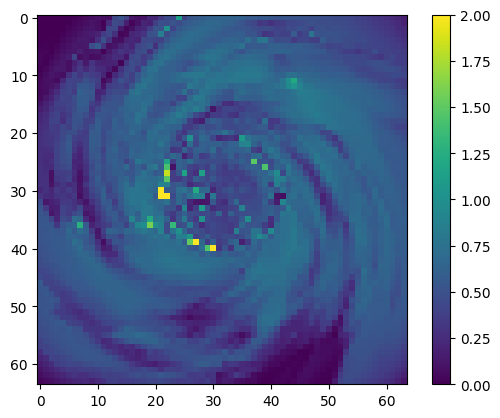

In [24]:
plt.imshow(res1[:,:,0]/np.pi*180)
plt.colorbar()
plt.clim(0,2)

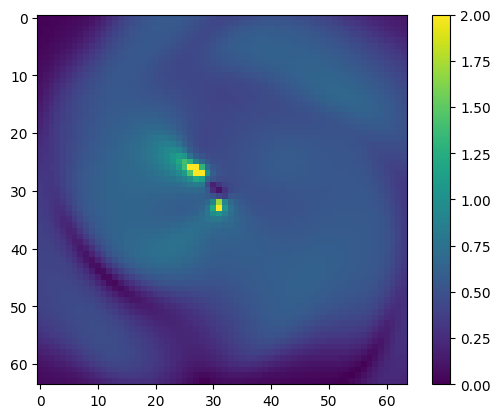

In [27]:
plt.imshow(res1[:,:,0]/np.pi*180)
plt.colorbar()
plt.clim(0,2)